# Day 25 — OrderPath ShapeNet: uncertainty-aware crystalline/amorphous boundary detection
**ATHENA CAMM Hackathon | Challenge 1 (SiSb) | Research prototype**  
**Prepared for Newsha Javanmardi**  

**Source of challenge:** [KalininGroup ATHENA CAMM Day 25 repository](https://github.com/KalininGroup/athena_camm_hackathon/tree/k4my4r/docs/day_25_12112026), especially [`shapeNet_data_.ipynb`](https://github.com/KalininGroup/athena_camm_hackathon/blob/k4my4r/docs/day_25_12112026/shapeNet_data_.ipynb). The source asks for a lightweight, geometry-aware detector of the interface between crystalline and amorphous SiSb, with an overlay on the STEM image. The challenge is exploratory, and does **not** supply pixel-level ground truth in the notebook.

### Proposed contribution — OrderPath
A *lightweight, physically interpretable* interface estimator with three complementary ingredients:
1. **Local periodic-order descriptors** (oriented Gabor energy and spectral concentration), local gradient anisotropy, and texture entropy rather than raw intensity alone.
2. **Weakly supervised small multilayer perceptron (ShapeNet-lite) and random forest** trained on a synthetic image with known boundary, plus a **no-training gradient baseline** for an honest comparison.
3. **Continuity-aware shortest path** through the learned boundary probability, followed by a **bootstrap uncertainty band**. A local high score alone can jump between unrelated features; the path model discourages those jumps.

We provide a seeded synthetic benchmark with known ground truth and a pathway to apply the same approach to a user-uploaded real SiSb image. **Synthetic scores are not evidence of accuracy on real microscopy.** No claim of improvement on real SiSb is made without annotated images.

## 1. Environment and reproducibility
Runs on Colab CPU using standard Python, NumPy, SciPy, scikit-image, scikit-learn and matplotlib. The demo is self-contained: it does **not** download the large SiSb `.emd` dataset automatically.

In [1]:
import sys, subprocess, importlib.util
required = {'numpy':'numpy','scipy':'scipy','matplotlib':'matplotlib','skimage':'scikit-image','sklearn':'scikit-learn','PIL':'Pillow'}
missing = [pip for module,pip in required.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import numpy as np, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, sobel, uniform_filter, map_coordinates
from scipy.signal import fftconvolve
from skimage.filters import gabor, rank
from skimage.morphology import disk
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.ndimage import binary_dilation
SEED=26; rng=np.random.default_rng(SEED)
print('Ready: deterministic random seed',SEED)

Ready: deterministic random seed 26


## 2. Synthetic STEM-like SiSb interface with held-out ground truth
A crystal-like periodic pattern lies above a curved interface; amorphous texture lies below. Gaussian noise, contrast drift and imaging blur are added. **This is synthetic training/testing, not observed SiSb physics.** Two independent seeds are used to avoid assessing a model on its training image.

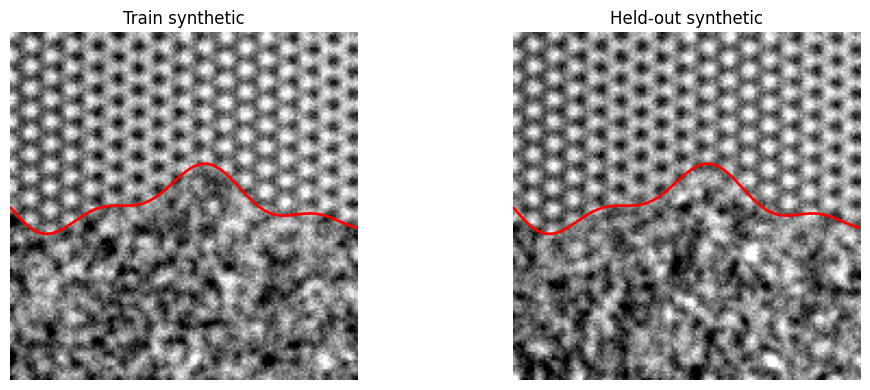

In [2]:
def synthetic_sisb(n=160, seed=0):
    rr=np.random.default_rng(seed)
    Y,X=np.mgrid[:n,:n]
    true_y=0.48*n + 12*np.sin(2*np.pi*X[0]/n*1.3+0.3) + 5*np.sin(2*np.pi*X[0]/n*3.1)
    yy=Y-true_y[None,:]
    lattice=(np.cos(2*np.pi*X/9)+np.cos(2*np.pi*(0.44*X+0.90*Y)/9)+np.cos(2*np.pi*(-0.47*X+0.88*Y)/9))/3
    texture=gaussian_filter(rr.standard_normal((n,n)),1.5)
    texture=texture/(texture.std()+1e-9)
    crystal=0.54+0.29*lattice
    amorph=0.49+0.11*texture
    mix=1/(1+np.exp(np.clip(yy/1.7,-40,40)))
    img=mix*crystal+(1-mix)*amorph
    img=gaussian_filter(img,0.8)+0.04*rr.standard_normal((n,n))+0.06*(X/n)
    img=(img-np.percentile(img,1))/(np.percentile(img,99)-np.percentile(img,1)+1e-9)
    return np.clip(img,0,1), true_y, mix>0.5
train_img, train_true, train_crystal=synthetic_sisb(seed=17)
test_img, test_true, test_crystal=synthetic_sisb(seed=99)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for a,im,bnd,label in zip(ax,[train_img,test_img],[train_true,test_true],['Train synthetic','Held-out synthetic']):
    a.imshow(im,cmap='gray'); a.plot(np.arange(len(bnd)),bnd,'r-',lw=2,label='Known boundary'); a.set_title(label); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Interpretable geometry descriptors
Gabor filters measure local directional periodicity. Other channels quantify local variability, gradient strength, structure-tensor anisotropy, and patch spectral concentration. None of the descriptors requires an expensive deep network. For the synthetic experiment we use a lightweight, six-channel feature tensor.

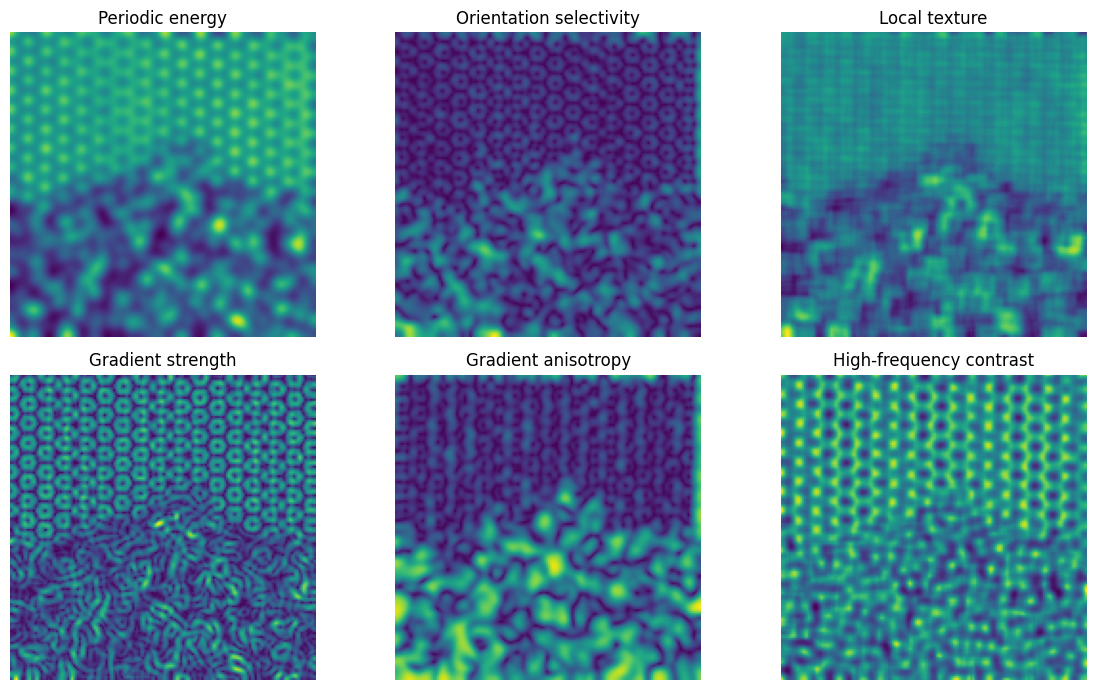

In [3]:
def features(image):
    im=np.asarray(image,float)
    im=(im-np.percentile(im,1))/(np.percentile(im,99)-np.percentile(im,1)+1e-9)
    im=np.clip(im,0,1)
    # Gabor filters at lattice-like wavelength; local energy at 3 orientations
    energies=[]
    for theta in (0,np.pi/3,2*np.pi/3):
        re,imag=gabor(im,frequency=1/9,theta=theta,sigma_x=3,sigma_y=3)
        energies.append(gaussian_filter(np.hypot(re,imag),2.5))
    en=np.stack(energies)
    periodic=np.mean(en,axis=0)
    orient=np.std(en,axis=0)/(periodic+1e-4)
    local_mean=uniform_filter(im,size=11)
    local_std=np.sqrt(np.maximum(uniform_filter(im*im,size=11)-local_mean**2,0))
    gx=sobel(gaussian_filter(im,1),axis=1); gy=sobel(gaussian_filter(im,1),axis=0)
    grad=np.hypot(gx,gy)
    jxx=gaussian_filter(gx*gx,3); jyy=gaussian_filter(gy*gy,3); jxy=gaussian_filter(gx*gy,3)
    anis=np.sqrt((jxx-jyy)**2+4*jxy*jxy)/(jxx+jyy+1e-8)
    # local high-frequency contrast vs overall contrast
    high=np.abs(im-gaussian_filter(im,3))
    contrast=gaussian_filter(high,2)/(local_std+1e-3)
    return np.stack((periodic,orient,local_std,grad,anis,contrast),axis=-1)
F_train=features(train_img); F_test=features(test_img)
fig,ax=plt.subplots(2,3,figsize=(12,7))
for a,v,name in zip(ax.ravel(),np.moveaxis(F_test,-1,0),['Periodic energy','Orientation selectivity','Local texture','Gradient strength','Gradient anisotropy','High-frequency contrast']):
    a.imshow(v,cmap='viridis');a.set_title(name);a.axis('off')
plt.tight_layout();plt.show()

## 4. Weakly supervised classifier
Training labels come **only** from the separate synthetic training image. The ±5-pixel transition region is excluded to avoid forcing ambiguous interfacial pixels into either class. Training samples are balanced so the model cannot exploit area imbalance. This model is a proof of concept and should be retrained with real annotated SiSb images for deployment.

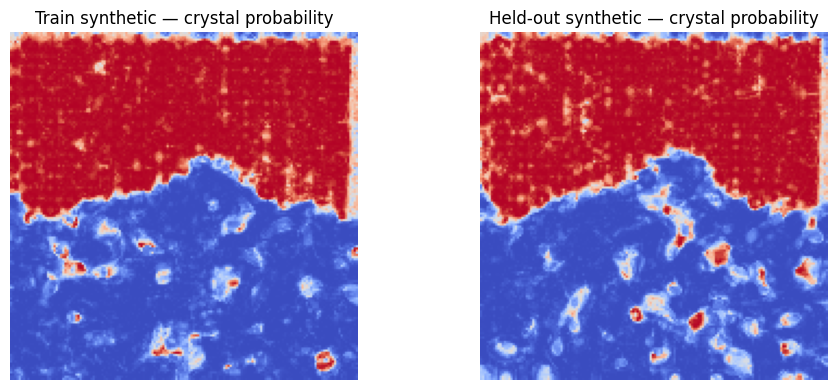

In [4]:
def fit_classifier(im, true_y, seed=26):
    F=features(im); n,h=im.shape
    Y,X=np.indices(im.shape)
    dist=Y-true_y[X]
    valid=np.abs(dist)>5
    ys=(dist[valid]<0).astype(int); xs=F[valid]
    random=np.random.default_rng(seed)
    chosen=[]
    for cl in (0,1):
        idx=np.where(ys==cl)[0];chosen.append(random.choice(idx,min(2500,len(idx)),replace=False))
    chosen=np.r_[tuple(chosen)]
    rf=RandomForestClassifier(n_estimators=80,max_depth=10,min_samples_leaf=7,max_features='sqrt',random_state=seed,n_jobs=-1)
    rf.fit(xs[chosen],ys[chosen]);return rf
model=fit_classifier(train_img,train_true)
P_train=model.predict_proba(F_train.reshape(-1,6))[:,1].reshape(train_img.shape)
P_test=model.predict_proba(F_test.reshape(-1,6))[:,1].reshape(test_img.shape)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,p,t in zip(ax,[P_train,P_test],['Train synthetic','Held-out synthetic']):a.imshow(p,cmap='coolwarm',vmin=0,vmax=1);a.set_title(t+' — crystal probability');a.axis('off')
plt.tight_layout();plt.show()

## 5. Structured path decoding: continuity matters
We calculate a boundary evidence map from the **vertical change in predicted crystalline probability**. Dynamic programming finds one boundary pixel per image column, penalizing abrupt vertical jumps. This encodes an explicit geometric prior (interfaces are locally continuous), not a post hoc graphical smoothing trick.

**Assumption:** here the interface is representable as `y(x)` (single-valued and mostly horizontal). It is unsuitable for overhangs, islands, vertical or branched interfaces unless the image is rotated or a graph-based contour method is substituted.

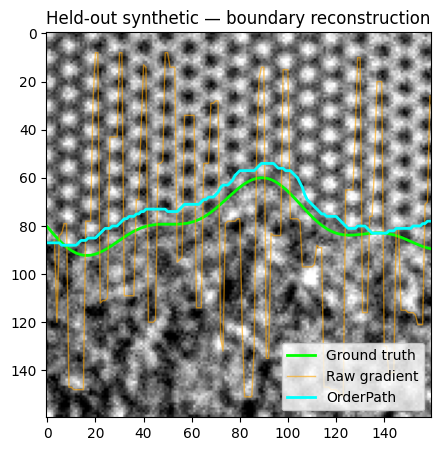

In [5]:
def boundary_evidence(p):
    return gaussian_filter(np.abs(sobel(gaussian_filter(p,1.0),axis=0)),1.3)
def shortest_boundary(evidence, smooth=0.22, max_step=6, margin=8):
    e=np.asarray(evidence,float)
    H,W=e.shape
    z=e/(np.percentile(e,99)+1e-8)
    costs=np.full((H,W),np.inf); parent=np.full((H,W),-1,np.int16)
    costs[margin:H-margin,0]=-z[margin:H-margin,0]
    for x in range(1,W):
        for y in range(margin,H-margin):
            lo=max(margin,y-max_step);hi=min(H-margin,y+max_step+1)
            ys=np.arange(lo,hi)
            candidate=costs[lo:hi,x-1]+smooth*(ys-y)**2
            best=np.argmin(candidate)
            costs[y,x]=candidate[best]-z[y,x]
            parent[y,x]=ys[best]
    end=int(np.argmin(costs[:,W-1]));out=np.empty(W,float)
    for x in range(W-1,-1,-1):
        out[x]=end
        if x: end=int(parent[end,x])
    return out
pred=shortest_boundary(boundary_evidence(P_test),smooth=0.1)
# Simple intensity-gradient baseline: best row per column (no continuity)
raw=gaussian_filter(np.abs(sobel(gaussian_filter(test_img,1),axis=0)),2)
base=np.argmax(raw[8:-8],axis=0)+8
fig,ax=plt.subplots(figsize=(10,5));ax.imshow(test_img,cmap='gray')
ax.plot(test_true,'lime',lw=2,label='Ground truth');ax.plot(base,'orange',alpha=.6,lw=1,label='Raw gradient');ax.plot(pred,'cyan',lw=2,label='OrderPath')
ax.legend(loc='lower right');ax.set_title('Held-out synthetic — boundary reconstruction');plt.show()

## 6. Quantitative benchmark and honest controls
Metrics in **pixels**: mean absolute boundary error (MAE), 95th-percentile error, maximum error and boundary jump rate (fraction of column-to-column movements greater than 3 pixels). Use the **held-out** image only for reporting. This single synthetic test is illustrative and cannot establish generalization to experimental images.

In [6]:
def boundary_metrics(path,truth):
    e=np.abs(np.asarray(path)-truth)
    return dict(MAE_px=float(e.mean()),P95_px=float(np.quantile(e,.95)),Max_px=float(e.max()),Jump_rate=float((np.abs(np.diff(path))>3).mean()))
results={'Raw gradient':boundary_metrics(base,test_true),'OrderPath (RF + path)':boundary_metrics(pred,test_true)}
for k,v in results.items():print(k,':',', '.join(f'{name}={val:.3f}' for name,val in v.items()))
print('Synthetic MAE difference (baseline - OrderPath):',round(results['Raw gradient']['MAE_px']-results['OrderPath (RF + path)']['MAE_px'],3),'px')

Raw gradient : MAE_px=37.506, P95_px=74.979, Max_px=90.155, Jump_rate=0.333
OrderPath (RF + path) : MAE_px=5.594, P95_px=8.910, Max_px=11.373, Jump_rate=0.000
Synthetic MAE difference (baseline - OrderPath): 31.911 px


## 6b. ShapeNet-lite: an actual compact neural network + ablation
The official challenge specifically invites a **lightweight neural network**. A small multilayer perceptron (MLP: six geometry inputs → 16 → 8 → two output probabilities) is trained on the same synthetic labels. It has a small inference footprint and can be compared with the random-forest path predictor. Both are tested on the same **held-out synthetic image**, not on the training data. This is *not* a deep end-to-end segmentation network; geometry features are computed separately.

MLP training iterations: 37
Raw gradient | MAE: 37.506 px | P95: 74.979 px
OrderPath (RF + path) | MAE: 5.594 px | P95: 8.910 px
ShapeNet-lite (MLP + path) | MAE: 5.488 px | P95: 8.652 px


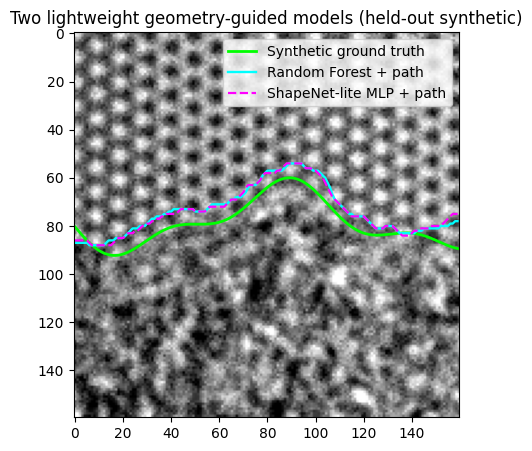

In [7]:
from sklearn.neural_network import MLPClassifier
Y,X=np.indices(train_img.shape);signed=Y-train_true[X];good=np.abs(signed)>5
x=F_train[good];y=(signed[good]<0).astype(int)
rr=np.random.default_rng(SEED)
sampled=np.concatenate([rr.choice(np.where(y==cl)[0],2000,replace=False) for cl in (0,1)])
scaler=StandardScaler().fit(x[sampled])
shapenet_lite=MLPClassifier(hidden_layer_sizes=(16,8),activation='relu',random_state=SEED,
                            early_stopping=True,max_iter=160,n_iter_no_change=10)
shapenet_lite.fit(scaler.transform(x[sampled]),y[sampled])
mlp_prob=shapenet_lite.predict_proba(scaler.transform(F_test.reshape(-1,6)))[:,1].reshape(test_img.shape)
mlp_path=shortest_boundary(boundary_evidence(mlp_prob),smooth=.1)
results['ShapeNet-lite (MLP + path)']=boundary_metrics(mlp_path,test_true)
print('MLP training iterations:',shapenet_lite.n_iter_)
for name,values in results.items():
    print(name, '| MAE:',f"{values['MAE_px']:.3f}",'px | P95:',f"{values['P95_px']:.3f}",'px')
fig,ax=plt.subplots(figsize=(10,5));ax.imshow(test_img,cmap='gray');ax.plot(test_true,'lime',label='Synthetic ground truth',lw=2)
ax.plot(pred,'cyan',label='Random Forest + path',lw=1.7);ax.plot(mlp_path,'magenta',label='ShapeNet-lite MLP + path',lw=1.6,ls='--')
ax.legend();ax.set_title('Two lightweight geometry-guided models (held-out synthetic)');plt.show()

## 7. Sensitivity and uncertainty: no misleading confidence interval
Bootstrap multiple **synthetic training resamples** and refit shallow classifiers, producing an ensemble of boundary paths. Their spread is an *algorithmic stability interval* conditional on our synthetic generator and fitted model—not a calibrated 95% confidence interval for a physical SiSb boundary. A defensible experimental uncertainty requires ground-truth annotations and calibration.

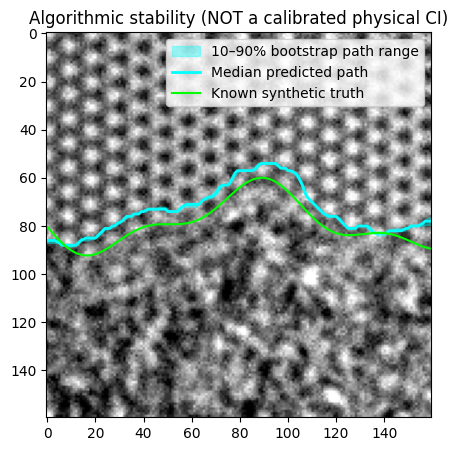

Median width of 10–90% algorithmic path range: 0.5 pixels


In [8]:
def bootstrap_paths(train_F,train_true,eval_F,replicates=6,seed=26):
    rg=np.random.default_rng(seed); H,W=train_F.shape[:2]
    Y,X=np.indices((H,W)); signed=Y-train_true[X]; valid=np.abs(signed)>5
    xx=train_F[valid]; yy=(signed[valid]<0).astype(int)
    byclass=[np.where(yy==c)[0] for c in (0,1)];paths=[]
    for rep in range(replicates):
        ix=np.concatenate([rg.choice(z,1400,replace=True) for z in byclass])
        clf=RandomForestClassifier(n_estimators=35,max_depth=9,min_samples_leaf=8,random_state=seed+rep,n_jobs=-1)
        clf.fit(xx[ix],yy[ix])
        pr=clf.predict_proba(eval_F.reshape(-1,6))[:,1].reshape(eval_F.shape[:2])
        paths.append(shortest_boundary(boundary_evidence(pr),smooth=.1))
    return np.asarray(paths)
paths=bootstrap_paths(F_train,train_true,F_test)
lo,mid,hi=np.quantile(paths,[.10,.5,.90],axis=0)
fig,ax=plt.subplots(figsize=(10,5));ax.imshow(test_img,cmap='gray');ax.fill_between(np.arange(test_img.shape[1]),lo,hi,color='cyan',alpha=.35,label='10–90% bootstrap path range');ax.plot(mid,color='cyan',lw=2,label='Median predicted path');ax.plot(test_true,color='lime',lw=1.5,label='Known synthetic truth');ax.set_title('Algorithmic stability (NOT a calibrated physical CI)');ax.legend();plt.show()
print('Median width of 10–90% algorithmic path range:',round(float(np.median(hi-lo)),2),'pixels')

## 8. Real SiSb microscopy image — OPTIONAL user upload
The official Day 25 repository shows how to load `.emd` files via `pyTEMlib` and references an external Google Drive dataset. This notebook **does not package or redistribute that data**. For the quickest Colab test, export one HAADF frame to `.png/.tif/.npy` and upload it here. To read `.emd`, use the official loader or install `pyTEMlib` separately.

**Important domain-shift warning:** the model was fitted on synthetic patterns. The overlay on real data is a qualitative hypothesis only; it **must not** be called validated detection without manual boundary annotations. For images with a vertical interface, rotate by 90 degrees before fitting the path.

In [9]:
# Optional real-image workflow. Set USE_REAL_IMAGE=True in Google Colab to upload an image.
USE_REAL_IMAGE=False
if USE_REAL_IMAGE:
    from google.colab import files
    from PIL import Image
    import io
    uploaded=files.upload();name=next(iter(uploaded))
    if name.lower().endswith('.npy'):
        im_real=np.load(io.BytesIO(uploaded[name]),allow_pickle=False)
    else:
        im_real=np.asarray(Image.open(io.BytesIO(uploaded[name])).convert('F'))
    if im_real.ndim!=2:raise ValueError('Expected one grayscale 2D STEM frame')
    # Resize long images to manage CPU/memory; pixel coordinates refer to resized image.
    from skimage.transform import resize
    scale=min(1.,256/max(im_real.shape))
    if scale<1: im_real=resize(im_real,(max(32,int(im_real.shape[0]*scale)),max(32,int(im_real.shape[1]*scale))),anti_aliasing=True)
    if min(im_real.shape)<40:raise ValueError('Image too small for this spatial feature scale')
    FF=features(im_real)
    pp=model.predict_proba(FF.reshape(-1,6))[:,1].reshape(im_real.shape)
    real_path=shortest_boundary(boundary_evidence(pp),smooth=.1,margin=8)
    fig,ax=plt.subplots(1,3,figsize=(15,5))
    ax[0].imshow(im_real,cmap='gray');ax[0].set_title('Input real microscopy')
    ax[1].imshow(pp,cmap='coolwarm',vmin=0,vmax=1);ax[1].set_title('Synthetic-trained order probability')
    ax[2].imshow(im_real,cmap='gray');ax[2].plot(real_path,color='cyan',lw=2);ax[2].set_title('Candidate interface — unvalidated')
    for a in ax:a.axis('off')
    plt.tight_layout();plt.show()
else:
    print('Real-image test skipped. Set USE_REAL_IMAGE=True to upload a real SiSb frame in Colab.')

Real-image test skipped. Set USE_REAL_IMAGE=True to upload a real SiSb frame in Colab.


## 9. What is actually novel, what remains open?
**Proposed methodological integration (not a claim of published novelty):** use symmetry/texture-informed local features, a compact learned probability model, a global continuity prior, and a bootstrap stability map *together* for microscopy interface detection. Each component has precedents; the distinct proposal is their task-specific coupling and transparent evaluation.

**Why this is better motivated than a raw threshold:** crystalline/amorphous discrimination depends on spatial order, not necessarily brightness; geometrical consistency prevents isolated false positives from becoming jagged interfaces; ensembles identify unstable segments for a future human-in-the-loop annotation workflow.

**Limitations:** simulated crystallinity is not representative of all SiSb orientations; fixed Gabor wavelength is sensitive to magnification and lattice spacing; model trained on synthetic labels may have severe domain shift; 1D path parameterization assumes a single-valued boundary; bootstrap intervals are not calibrated probabilities. **Do not report synthetic results as experimental performance.**

**Next experiment to support a publishable claim:** manually mark 10–20 real SiSb boundaries across varied image orientations and contrast; hold out entire images; compare raw gradients, handcrafted-order+threshold, RF-only boundary, RF+path, ShapeNet-lite MLP+path, and RF+path+bootstrap; report MAE, tolerance-based F1, runtime, failure cases, and annotation uncertainty; ablate Gabor channels and smoothness strength. Repeat across pixel sizes and rotations.

**Upload policy:** this notebook is an independent solution. Save as `Newsha_Day25_OrderPath_ShapeNet.ipynb` under `docs/day_25_12112026/` in your fork and submit a PR; do not overwrite other participants' work. Before PR, run the synthetic cells, optionally test real data, and ensure the notebook name and links are correct.